In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
import subprocess
import shutil

if shutil.which("nvidia-smi"):
    result = subprocess.run(
        ["nvidia-smi"],
        capture_output=True,
        text=True
    )
    print(result.stdout or result.stderr)
else:
    print("No NVIDIA GPU tool found.")

try:
    import tensorflow as tf

    print("TensorFlow version:", tf.__version__)
    gpus = tf.config.list_physical_devices("GPU")
    print("TensorFlow GPU count:", len(gpus))

    for gpu in gpus:
        details = tf.config.experimental.get_device_details(gpu)
        print("GPU:", details.get("device_name", gpu.name))

except ImportError as error:
    print("TensorFlow import error:", error)

Tue Nov 17 15:56:07 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [1]:
from pathlib import Path

root = Path("/kaggle/input")
print("=== Attached input files (first 60) ===")

count = 0
for path in root.rglob("*"):
    if path.is_file():
        print(path.relative_to(root))
        count += 1
        if count >= 60:
            print("... listing stopped at 60 files")
            break

if count == 0:
    print("No input files found. Attach your private Dataset first.")

=== Attached input files (first 60) ===
datasets/kinglam0916/dit5411-handwriting-training/DIT5411_project/augmentation_preview.png
datasets/kinglam0916/dit5411-handwriting-training/DIT5411_project/baseline_cnn_architecture.json
datasets/kinglam0916/dit5411-handwriting-training/DIT5411_project/baseline_cnn_summary.txt
datasets/kinglam0916/dit5411-handwriting-training/DIT5411_project/class_mapping.json
datasets/kinglam0916/dit5411-handwriting-training/DIT5411_project/development_augmentation_plan.npz
datasets/kinglam0916/dit5411-handwriting-training/DIT5411_project/development_manifest.csv
datasets/kinglam0916/dit5411-handwriting-training/DIT5411_project/experiment_config.json
datasets/kinglam0916/dit5411-handwriting-training/DIT5411_project/original_samples_manifest.csv
datasets/kinglam0916/dit5411-handwriting-training/DIT5411_project/split_draft_summary.json
datasets/kinglam0916/dit5411-handwriting-training/DIT5411_project/training_batch_preview.png
datasets/kinglam0916/dit5411-handwri

In [1]:
from pathlib import Path
import shutil
import zipfile

INPUT = Path("/kaggle/input")
WORK = Path("/kaggle/working")
OUTPUT = WORK / "handwriting_dataset"
MERGED = WORK / "all_data_merged.zip"

# Locate the first volume.
matches = list(INPUT.rglob("all_data.zip.001"))
if len(matches) != 1:
    raise RuntimeError(
        f"Found {len(matches)} first volumes. "
        "Attach the correct Dataset Version 2 only."
    )

source = matches[0].parent
parts = [source / f"all_data.zip.{i:03d}" for i in range(1, 13)]

missing = [p.name for p in parts if not p.is_file()]
if missing:
    raise FileNotFoundError(f"Missing volumes: {missing}")

total = sum(p.stat().st_size for p in parts)
if shutil.disk_usage(WORK).free < total:
    raise RuntimeError("Not enough disk space to merge the volumes.")

print("Merging 12 volumes...")
with MERGED.open("wb") as destination:
    for part in parts:
        print("Adding:", part.name)
        with part.open("rb") as stream:
            shutil.copyfileobj(stream, destination, length=8 * 1024 * 1024)

if not zipfile.is_zipfile(MERGED):
    raise RuntimeError(
        "Merged file is not a readable ZIP. "
        "Stop here and share this output; do not extract volumes separately."
    )

with zipfile.ZipFile(MERGED) as archive:
    entries = archive.infolist()
    unpacked = sum(entry.file_size for entry in entries)

    print(f"Archive entries: {len(entries):,}")
    print(f"Uncompressed size: {unpacked / 1024**3:.2f} GiB")

    if shutil.disk_usage(WORK).free < unpacked + 1024**3:
        raise RuntimeError(
            "Not enough free disk space for extraction plus 1 GiB reserve."
        )

    # Reject paths that would escape the destination folder.
    root = OUTPUT.resolve()
    for entry in entries:
        target = (root / entry.filename).resolve()
        if not target.is_relative_to(root):
            raise RuntimeError(f"Unsafe archive path: {entry.filename}")

    OUTPUT.mkdir(parents=True, exist_ok=True)
    print("Extracting... Please wait.")
    archive.extractall(OUTPUT)

# Remove only the temporary merged ZIP after successful extraction.
MERGED.unlink()

print("\nExtraction complete:", OUTPUT)
print("\nTop-level extracted items:")
for path in sorted(OUTPUT.iterdir())[:20]:
    print(path.name, "(folder)" if path.is_dir() else "(file)")

print("\nTraining script locations:")
for path in INPUT.rglob("training_core.py"):
    print(path)

Merging 12 volumes...
Adding: all_data.zip.001
Adding: all_data.zip.002
Adding: all_data.zip.003
Adding: all_data.zip.004
Adding: all_data.zip.005
Adding: all_data.zip.006
Adding: all_data.zip.007
Adding: all_data.zip.008
Adding: all_data.zip.009
Adding: all_data.zip.010
Adding: all_data.zip.011
Adding: all_data.zip.012
Archive entries: 697,743
Uncompressed size: 1.18 GiB
Extracting... Please wait.

Extraction complete: /kaggle/working/handwriting_dataset

Top-level extracted items:
cleaned_data (folder)

Training script locations:
/kaggle/input/datasets/kinglam0916/dit5411-handwriting-training/DIT5411_latest_project/DIT5411_project/training_core.py


In [2]:
from pathlib import Path
import shutil
import pandas as pd

INPUT = Path("/kaggle/input")
PROJECT = Path("/kaggle/working/DIT5411_project")
DATA_ROOT = Path("/kaggle/working/handwriting_dataset/cleaned_data")

scripts = list(INPUT.rglob("training_core.py"))
if len(scripts) != 1:
    raise RuntimeError(f"Expected one training_core.py, found {len(scripts)}")

if not DATA_ROOT.is_dir():
    raise FileNotFoundError(
        f"Data folder missing: {DATA_ROOT}. "
        "If the session was reset, rerun the extraction cell."
    )

# Restore the project without overwriting existing working files.
source_project = scripts[0].parent
PROJECT.mkdir(parents=True, exist_ok=True)

for source in source_project.rglob("*"):
    if source.is_file():
        destination = PROJECT / source.relative_to(source_project)
        destination.parent.mkdir(parents=True, exist_ok=True)
        if not destination.exists():
            shutil.copy2(source, destination)

print("=== PROJECT LOCATION ===")
print(PROJECT)

print("\n=== DATA FOLDER: FIRST 10 ITEMS ===")
from itertools import islice
for path in islice(DATA_ROOT.iterdir(), 10):
    print(path.name, "(folder)" if path.is_dir() else "(file)")

print("\n=== EXPERIMENT CONFIG ===")
config = PROJECT / "experiment_config.json"
print(config.read_text(encoding="utf-8"))

print("\n=== DEVELOPMENT MANIFEST: FIRST 3 ROWS ===")
manifest = PROJECT / "development_manifest.csv"
preview = pd.read_csv(manifest, nrows=3)
print("Columns:", preview.columns.tolist())
print(preview.to_string(index=False))

print("\n=== TRAINING CORE SOURCE ===")
print((PROJECT / "training_core.py").read_text(encoding="utf-8"))

=== PROJECT LOCATION ===
/kaggle/working/DIT5411_project

=== DATA FOLDER: FIRST 10 ITEMS ===
12379 (folder)
2389 (folder)
9375 (folder)
432 (folder)
3618 (folder)
9272 (folder)
4738 (folder)
2501 (folder)
3712 (folder)
6640 (folder)

=== EXPERIMENT CONFIG ===
{
  "seed": 2026,
  "num_classes": 13065,
  "image_size": [
    128,
    128
  ],
  "color_mode": "grayscale",
  "validation_images_per_class": 4,
  "development_training_items_per_class": 200,
  "short_class_policy": "Use all available original images as the training pool; reserve 4 per class for development validation. No test images exist for these 43 classes. This exception has not been approved by the instructor.",
  "test_class_coverage": 13022,
  "augmentation_status": "Plan only; transformed images not generated yet",
  "final_refit_policy": "After selecting settings using validation, rebuild training from train plus validation, without using test images.",
  "augmentation_parameters": {
    "rotation_degrees": [
      -9

In [4]:
from pathlib import Path
from itertools import islice
import pandas as pd

DATA = Path("/kaggle/working/handwriting_dataset/cleaned_data")
PROJECT = Path("/kaggle/working/DIT5411_project")

df = pd.read_csv(
    PROJECT / "development_manifest.csv",
    encoding="utf-8-sig",
    keep_default_na=False
)

sample = df.sample(n=min(20, len(df)), random_state=2026)
missing_rows = sample[
    ~sample["relative_path"].map(lambda p: (DATA / p).is_file())
]

print("Data root exists:", DATA.is_dir())
print("Missing in sample:", len(missing_rows), "/", len(sample))

for relative in missing_rows["relative_path"].head(3):
    expected = DATA / relative
    folder = expected.parent

    print("\n=== EXPECTED ===")
    print(repr(str(expected)))
    print("Parent folder exists:", folder.is_dir())

    if folder.is_dir():
        print("Actual filenames (first 10):")
        for path in islice(folder.iterdir(), 10):
            print(repr(path.name), "(folder)" if path.is_dir() else "(file)")
    else:
        print("Data root entries (first 10):")
        for path in islice(DATA.iterdir(), 10):
            print(repr(path.name))

Data root exists: True
Missing in sample: 20 / 20

=== EXPECTED ===
'/kaggle/working/handwriting_dataset/cleaned_data/388/介_42.png'
Parent folder exists: True
Actual filenames (first 10):
'ñ╢_23.png' (file)
'ñ╢_11.png' (file)
'ñ╢_49.png' (file)
'ñ╢_20.png' (file)
'ñ╢_44.png' (file)
'ñ╢_28.png' (file)
'ñ╢_18.png' (file)
'ñ╢_16.png' (file)
'ñ╢_38.png' (file)
'ñ╢_45.png' (file)

=== EXPECTED ===
'/kaggle/working/handwriting_dataset/cleaned_data/8358/跎_55.png'
Parent folder exists: True
Actual filenames (first 10):
'╢Y_24.png' (file)
'╢Y_40.png' (file)
'╢Y_48.png' (file)
'╢Y_2.png' (file)
'╢Y_46.png' (file)
'╢Y_43.png' (file)
'╢Y_7.png' (file)
'╢Y_41.png' (file)
'╢Y_42.png' (file)
'╢Y_54.png' (file)

=== EXPECTED ===
'/kaggle/working/handwriting_dataset/cleaned_data/12009/它_34.png'
Parent folder exists: True
Actual filenames (first 10):
'Ñª_49.png' (file)
'Ñª_0.png' (file)
'Ñª_18.png' (file)
'Ñª_23.png' (file)
'Ñª_9.png' (file)
'Ñª_8.png' (file)
'Ñª_22.png' (file)
'Ñª_19.png' (file)
'Ñª_6.

In [5]:
from pathlib import Path
import pandas as pd

DATA = Path("/kaggle/working/handwriting_dataset/cleaned_data")
PROJECT = Path("/kaggle/working/DIT5411_project")

manifest = pd.read_csv(
    PROJECT / "development_manifest.csv",
    encoding="utf-8-sig",
    keep_default_na=False
)

relative_paths = manifest["relative_path"]
if relative_paths.duplicated().any():
    raise RuntimeError("Duplicate manifest paths found. Stop for inspection.")

# Work on a separate table; do not modify the original CSV.
table = pd.DataFrame({
    "folder": relative_paths.map(lambda p: str(Path(p).parent)),
    "filename": relative_paths.map(lambda p: Path(p).name)
})

changes = []
problems = []
already_correct = 0

print("Checking filename encodings against the original manifest...")

for folder, group in table.groupby("folder", sort=False):
    directory = DATA / folder
    if not directory.is_dir():
        problems.append(f"Missing folder: {directory}")
        continue

    actual_names = {
        p.name for p in directory.iterdir() if p.is_file()
    }
    expected_names = set(group["filename"])
    used_sources = set()

    for expected in group["filename"]:
        if expected in actual_names:
            already_correct += 1
            used_sources.add(expected)
            continue

        candidates = set()

        # Reproduce common legacy ZIP filename misdecodings.
        for encoding in ("big5", "cp950", "gbk", "gb18030", "utf-8"):
            try:
                candidate = expected.encode(encoding).decode("cp437")
            except UnicodeError:
                continue

            if candidate in actual_names:
                candidates.add(candidate)

        if len(candidates) != 1:
            problems.append(
                f"{folder}/{expected}: "
                f"{len(candidates)} matching encoded filenames"
            )
            continue

        actual = next(iter(candidates))

        # Reject ambiguous reuse or a source needed by another manifest row.
        if actual in used_sources or actual in expected_names:
            problems.append(f"Filename collision: {folder}/{actual}")
            continue

        used_sources.add(actual)
        changes.append((directory / actual, directory / expected))

print("Already correct:", already_correct)
print("Uniquely matched repairs:", len(changes))
print("Unresolved/conflicting paths:", len(problems))

# Complete preflight BEFORE renaming anything.
if problems:
    print("\nFirst 10 problems:")
    for message in problems[:10]:
        print(message)
    raise RuntimeError(
        "Preflight failed. No files renamed. Share this output."
    )

print("\nFirst 5 proposed repairs:")
for source, target in changes[:5]:
    print(repr(source.name), "->", repr(target.name))

print("\nAll manifest paths accounted for. Repairing filenames...")

for number, (source, target) in enumerate(changes, start=1):
    if target.exists():
        raise FileExistsError(f"Will not overwrite: {target}")
    source.rename(target)

    if number % 100000 == 0:
        print(f"Renamed {number:,} / {len(changes):,}")

print("\nVerifying all manifest paths...")
missing = [
    relative for relative in relative_paths
    if not (DATA / relative).is_file()
]

print("Missing paths after repair:", len(missing))
if missing:
    print(missing[:10])
    raise RuntimeError("Some paths are still missing. Stop here.")

print("SUCCESS: All manifest paths now exist.")
print("Image contents, labels, splits and augmentation plan unchanged.")

Checking filename encodings against the original manifest...
Already correct: 51
Uniquely matched repairs: 684626
Unresolved/conflicting paths: 0

First 5 proposed repairs:
'ñ@_0.png' -> '一_0.png'
'ñ@_1.png' -> '一_1.png'
'ñ@_2.png' -> '一_2.png'
'ñ@_3.png' -> '一_3.png'
'ñ@_4.png' -> '一_4.png'

All manifest paths accounted for. Repairing filenames...
Renamed 100,000 / 684,626
Renamed 200,000 / 684,626
Renamed 300,000 / 684,626
Renamed 400,000 / 684,626
Renamed 500,000 / 684,626
Renamed 600,000 / 684,626

Verifying all manifest paths...
Missing paths after repair: 0
SUCCESS: All manifest paths now exist.
Image contents, labels, splits and augmentation plan unchanged.


In [6]:
from pathlib import Path
import importlib.util
import tensorflow as tf

PROJECT = Path("/kaggle/working/DIT5411_project")
DATA = Path("/kaggle/working/handwriting_dataset/cleaned_data")

# 1. Check GPU.
gpus = tf.config.list_physical_devices("GPU")
print("TensorFlow GPU count:", len(gpus))

if not gpus:
    raise RuntimeError(
        "No GPU detected. Enable GPU T4 x2 in Settings first."
    )

for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass  # GPU may already be initialized.

    details = tf.config.experimental.get_device_details(gpu)
    print("GPU:", details.get("device_name", gpu.name))

# 2. Check restored files.
if not DATA.is_dir():
    raise FileNotFoundError(
        "Extracted data is missing. Stop here and share this output."
    )

script = PROJECT / "training_core.py"
if not script.is_file():
    raise FileNotFoundError(
        "training_core.py is missing. Stop here and share this output."
    )

# 3. Load existing training code and override Colab paths.
spec = importlib.util.spec_from_file_location(
    "training_core_kaggle", script
)
core = importlib.util.module_from_spec(spec)
spec.loader.exec_module(core)

core.PROJECT = PROJECT
core.DATA = DATA

tf.keras.utils.set_random_seed(core.SEED)

frame, paths, plan = core.load_metadata()

print("\nProject:", core.PROJECT)
print("Data:", core.DATA)
print("\nOriginal split counts:")
print(frame["split"].value_counts().to_string())

# 4. Quick sample check of repaired paths.
sample = frame.sample(
    n=min(20, len(frame)),
    random_state=core.SEED
)

missing = [
    str(DATA / relative)
    for relative in sample["relative_path"]
    if not (DATA / relative).is_file()
]

if missing:
    raise FileNotFoundError(
        f"Sample image paths missing: {missing[:5]}"
    )

# 5. Rebuild datasets using the original split and augmentation plan.
BATCH_SIZE = 32

train_ds = core.make_dataset(
    frame, paths, plan,
    "train",
    batch_size=BATCH_SIZE
)

validation_ds = core.make_dataset(
    frame, paths, plan,
    "validation",
    batch_size=BATCH_SIZE
)

images, labels = next(iter(train_ds))
TRAIN_STEPS = int(train_ds.cardinality().numpy())

print("\nBatch image shape:", images.shape)
print("Batch label shape:", labels.shape)
print("Training batches per epoch:", TRAIN_STEPS)
print(
    "Validation batches:",
    int(validation_ds.cardinality().numpy())
)
print("\nPipeline ready. Full training has NOT started.")

TensorFlow GPU count: 2
GPU: Tesla T4
GPU: Tesla T4

Project: /kaggle/working/DIT5411_project
Data: /kaggle/working/handwriting_dataset/cleaned_data

Original split counts:
split
train         469867
test          162550
validation     52260

Batch image shape: (32, 128, 128, 1)
Batch label shape: (32,)
Training batches per epoch: 81657
Validation batches: 1634

Pipeline ready. Full training has NOT started.


In [7]:
import time
import gc
import numpy as np

core.require_gpu()

WARMUP_BATCHES = 10
MEASURE_BATCHES = 50
TOTAL_BATCHES = WARMUP_BATCHES + MEASURE_BATCHES


class BatchTimer(tf.keras.callbacks.Callback):
    def __init__(self):
        super().__init__()
        self.seconds = []

    def on_train_batch_begin(self, batch, logs=None):
        self.started = time.perf_counter()

    def on_train_batch_end(self, batch, logs=None):
        if batch >= WARMUP_BATCHES:
            self.seconds.append(
                time.perf_counter() - self.started
            )


timer = BatchTimer()
benchmark_model = None

try:
    tf.keras.utils.set_random_seed(core.SEED)

    # Benchmark on one T4 first.
    with tf.device("/GPU:0"):
        benchmark_model = core.build_model("baseline")

    print("Baseline benchmark: 10 warm-up + 50 measured batches")
    print("No validation, test evaluation, or checkpoint saving.")
    print("First-run GPU initialization may take a little time.")

    started = time.perf_counter()

    history = benchmark_model.fit(
        train_ds.take(TOTAL_BATCHES),
        epochs=1,
        callbacks=[
            timer,
            tf.keras.callbacks.TerminateOnNaN()
        ],
        verbose=1
    )

    elapsed = time.perf_counter() - started

    if len(timer.seconds) != MEASURE_BATCHES:
        raise RuntimeError(
            "Benchmark did not finish all measured batches. "
            "Check the output above."
        )

    if not np.isfinite(history.history["loss"][-1]):
        raise RuntimeError(
            "Non-finite loss detected. Stop and share this output."
        )

    seconds_per_batch = float(np.mean(timer.seconds))
    estimated_train_hours = (
        seconds_per_batch * TRAIN_STEPS / 3600
    )

    print("\n=== GPU BENCHMARK RESULT ===")
    print(
        f"Total benchmark wall time: {elapsed:.1f} seconds"
    )
    print(
        f"Mean measured batch time: "
        f"{seconds_per_batch:.4f} seconds"
    )
    print(
        f"Approx. images/second: "
        f"{BATCH_SIZE / seconds_per_batch:.1f}"
    )
    print(
        "Estimated baseline training time per full epoch "
        f"(excluding validation): {estimated_train_hours:.2f} hours"
    )
    print(
        "Short-run estimate only; "
        "full-epoch speed may differ."
    )

finally:
    if benchmark_model is not None:
        del benchmark_model

    tf.keras.backend.clear_session()
    gc.collect()

    print(
        "\nBenchmark model discarded. "
        "No official checkpoint saved."
    )

Baseline benchmark: 10 warm-up + 50 measured batches
No validation, test evaluation, or checkpoint saving.
First-run GPU initialization may take a little time.


E0000 00:00:1794934182.028027     145 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


60/60 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - accuracy: 0.0000e+00 - loss: 9.4786 - top5_accuracy: 0.0000e+00

=== GPU BENCHMARK RESULT ===
Total benchmark wall time: 11.7 seconds
Mean measured batch time: 0.0314 seconds
Approx. images/second: 1019.9
Estimated baseline training time per full epoch (excluding validation): 0.71 hours
Short-run estimate only; full-epoch speed may differ.

Benchmark model discarded. No official checkpoint saved.


In [8]:
from pathlib import Path
import time
import tensorflow as tf

core.require_gpu()

if not core.DATA.is_dir():
    raise FileNotFoundError("Data folder missing. Stop here.")

run_dir = core.PROJECT / "runs" / "baseline"

# Never silently overwrite an existing run.
existing = [
    run_dir / name
    for name in ("best.keras", "last.keras", "history.csv")
    if (run_dir / name).exists()
]

if existing:
    raise RuntimeError(
        "Existing baseline run found. Do not overwrite or restart blindly. "
        "Share the existing history.csv output first."
    )

tf.keras.utils.set_random_seed(core.SEED)

print("Starting baseline: 1 complete development epoch")
print("Training batches:", int(train_ds.cardinality().numpy()))
print("Validation batches:", int(validation_ds.cardinality().numpy()))
print("Checkpoints will be saved to:", run_dir)
print("The test set will NOT be evaluated.")

started = time.perf_counter()

# Fresh model; use one GPU, as in the benchmark.
with tf.device("/GPU:0"):
    baseline_model = core.train_model(
        name="baseline",
        train_ds=train_ds,
        validation_ds=validation_ds,
        epochs=1,
        initial_epoch=0,
        resume=False
    )

print(
    "\nTraining + validation wall time:",
    f"{(time.perf_counter() - started) / 60:.1f} minutes"
)

print("\nSaved run files:")
for path in sorted(run_dir.iterdir()):
    if path.is_file():
        print(path.name, f"{path.stat().st_size / 1024**2:.1f} MiB")

Starting baseline: 1 complete development epoch
Training batches: 81657
Validation batches: 1634
Checkpoints will be saved to: /kaggle/working/DIT5411_project/runs/baseline
The test set will NOT be evaluated.
81657/81657 ━━━━━━━━━━━━━━━━━━━━ 2705s 33ms/step - accuracy: 6.4294e-05 - loss: 9.4943 - top5_accuracy: 3.1535e-04 - val_accuracy: 7.6540e-05 - val_loss: 9.4817 - val_top5_accuracy: 3.8270e-04

Training + validation wall time: 45.1 minutes

Saved run files:
best.keras 63.6 MiB
history.csv 0.0 MiB
last.keras 63.6 MiB


In [9]:
import pandas as pd
import zipfile
from IPython.display import display, FileLink

run_dir = core.PROJECT / "runs" / "baseline"
history_path = run_dir / "history.csv"

if not history_path.is_file():
    raise FileNotFoundError(
        "history.csv not found. Check whether training completed."
    )

print("=== BASELINE HISTORY ===")
history = pd.read_csv(history_path)
print(history.to_string(index=False))

for name in ("best.keras", "last.keras"):
    if not (run_dir / name).is_file():
        raise FileNotFoundError(f"Missing checkpoint: {name}")

backup = Path("/kaggle/working/baseline_epoch1_backup.zip")

# Include checkpoints, history and project configuration,
# but not the hundreds of thousands of original images.
with zipfile.ZipFile(
    backup, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for path in sorted(core.PROJECT.rglob("*")):
        if path.is_file():
            archive.write(
                path,
                arcname=(
                    Path("DIT5411_project")
                    / path.relative_to(core.PROJECT)
                ).as_posix()
            )

print(f"\nBackup created: {backup.stat().st_size / 1024**2:.1f} MiB")
display(FileLink("baseline_epoch1_backup.zip"))

=== BASELINE HISTORY ===
 epoch  accuracy     loss  top5_accuracy  val_accuracy  val_loss  val_top5_accuracy
     0  0.000064 9.494274       0.000315      0.000077  9.481735           0.000383

Backup created: 66.6 MiB


/kaggle/working/baseline_epoch1_backup.zip

=== 1. LABEL AND PLAN CHECK ===
Number of classes: 13065
Manifest label range: 0 to 13064
Chance accuracy: 7.654037504783774e-05
Uniform-prediction loss: 9.477692177954713
Plan rows checked: 10000
Plan/source label mismatches: 0
Plan sources outside train: 0

=== 2. RANDOM ORIGINAL TRAINING IMAGES ===
Image batch shape: (32, 128, 128, 1)
All pixels finite: True
Pixel min / max: 0.0 / 1.0000002
Per-image pixel std: min / median / max: 0.051661253 / 0.14125444 / 0.22388564
Unique true classes in sample: 32

=== 3. SAVED MODEL PREDICTIONS ===
True class IDs: [11739, 10359, 367, 6285, 10457, 11086, 717, 4876, 5233, 3048, 10739, 12171, 2611, 1709, 7183, 11034, 9054, 3529, 11978, 9992, 8108, 3884, 3064, 9686, 722, 724, 828, 7906, 2013, 9315, 157, 11715]
Predicted class IDs: [2059, 2059, 2059, 2059, 2059, 2059, 2059, 2059, 2059, 2059, 2059, 2059, 2059, 2059, 2059, 2059, 2059, 2059, 2059, 2059, 2059, 2059, 2059, 2059, 2059, 2059, 2059, 2059, 2059, 2059, 2059, 2059]
Unique predicted classes: 1


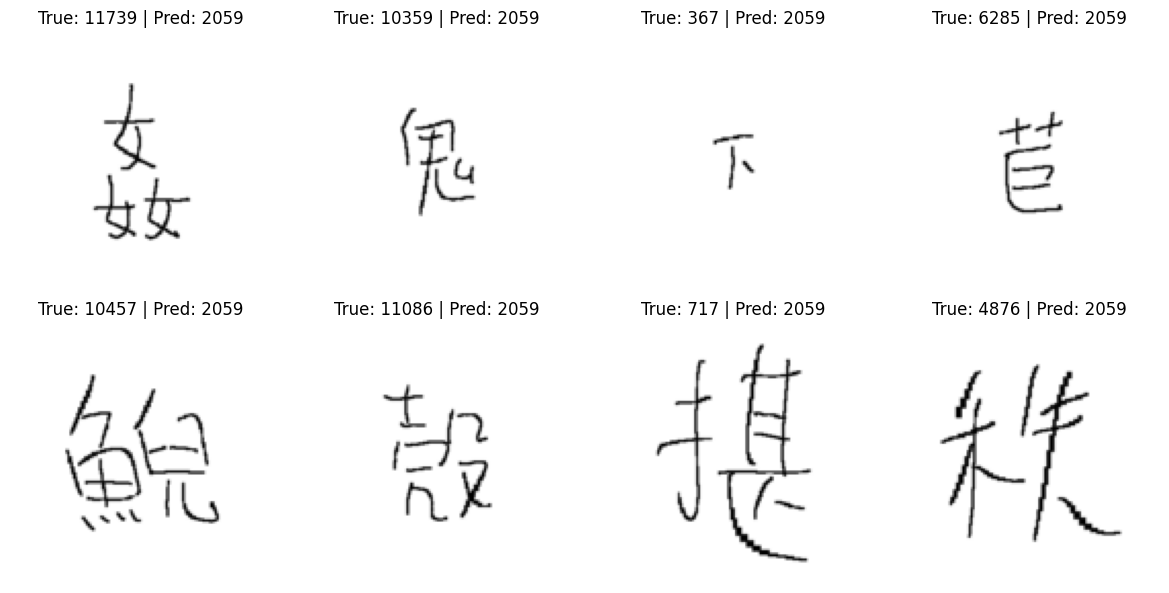


Inspection complete. No checkpoints changed.


In [10]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

print("=== 1. LABEL AND PLAN CHECK ===")
print("Number of classes:", core.CLASSES)
print(
    "Manifest label range:",
    frame["class_id"].min(),
    "to",
    frame["class_id"].max()
)
print("Chance accuracy:", 1 / core.CLASSES)
print("Uniform-prediction loss:", np.log(core.CLASSES))

# load_metadata() should have sorted rows by sample_index.
if not np.array_equal(
    frame["sample_index"].to_numpy(),
    np.arange(len(frame))
):
    raise RuntimeError("Manifest index order is incorrect.")

rng = np.random.default_rng(core.SEED)
plan_count = len(plan["source_index"])
positions = rng.choice(
    plan_count, size=min(10000, plan_count), replace=False
)

source_indices = np.asarray(
    plan["source_index"]
)[positions].astype(np.int64)

if np.any(source_indices < 0) or np.any(source_indices >= len(frame)):
    raise RuntimeError("Augmentation plan contains invalid source indices.")

source_rows = frame.iloc[source_indices]
planned_labels = np.asarray(plan["class_id"])[positions]

label_mismatches = np.count_nonzero(
    planned_labels != source_rows["class_id"].to_numpy()
)
non_train_sources = np.count_nonzero(
    source_rows["split"].to_numpy() != "train"
)

print("Plan rows checked:", len(positions))
print("Plan/source label mismatches:", label_mismatches)
print("Plan sources outside train:", non_train_sources)

if label_mismatches or non_train_sources:
    raise RuntimeError(
        "Plan check failed. Stop here and share the output."
    )

print("\n=== 2. RANDOM ORIGINAL TRAINING IMAGES ===")

sample_rows = frame.loc[frame["split"] == "train"].sample(
    n=32, random_state=core.SEED
)

# Same decoding/resizing as training, without augmentation.
image_list = []
for relative in sample_rows["relative_path"]:
    contents = tf.io.read_file(str(core.DATA / relative))
    image = tf.io.decode_png(contents, channels=1)
    image = tf.image.convert_image_dtype(image, tf.float32)
    image = tf.image.resize(
        image, [core.SIZE, core.SIZE], antialias=True
    )
    image_list.append(image)

x = tf.stack(image_list)
y = sample_rows["class_id"].to_numpy(dtype=np.int64)

pixels = x.numpy()
image_std = pixels.std(axis=(1, 2, 3))

print("Image batch shape:", x.shape)
print("All pixels finite:", np.isfinite(pixels).all())
print("Pixel min / max:", pixels.min(), "/", pixels.max())
print(
    "Per-image pixel std: min / median / max:",
    image_std.min(), "/", np.median(image_std), "/", image_std.max()
)
print("Unique true classes in sample:", len(np.unique(y)))

print("\n=== 3. SAVED MODEL PREDICTIONS ===")

checkpoint = core.PROJECT / "runs" / "baseline" / "last.keras"
diagnostic_model = tf.keras.models.load_model(
    checkpoint, compile=False
)

probabilities = diagnostic_model(x, training=False).numpy()

if not np.isfinite(probabilities).all():
    raise RuntimeError("Model predictions contain NaN or Inf.")

predicted = probabilities.argmax(axis=1)
confidence = probabilities.max(axis=1)

print("True class IDs:", y.tolist())
print("Predicted class IDs:", predicted.tolist())
print("Unique predicted classes:", len(np.unique(predicted)))
print(
    "Max probability: min / mean / max:",
    confidence.min(), "/", confidence.mean(), "/", confidence.max()
)
print(
    "Mean probability variation across images:",
    probabilities.std(axis=0).mean()
)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(
        pixels[i, :, :, 0],
        cmap="gray",
        vmin=0,
        vmax=1
    )
    ax.set_title(f"True: {y[i]} | Pred: {predicted[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

del diagnostic_model
print("\nInspection complete. No checkpoints changed.")

In [11]:
import numpy as np
import tensorflow as tf

if "x" not in globals():
    raise RuntimeError(
        "Image batch x is missing. Rerun the previous inspection cell first."
    )

checkpoint = core.PROJECT / "runs" / "baseline" / "last.keras"

model_check = tf.keras.models.load_model(
    checkpoint,
    compile=False
)

# Use 8 original training images from the previous inspection.
probe_images = tf.convert_to_tensor(x[:8], dtype=tf.float32)

layers_to_check = [
    layer for layer in model_check.layers
    if not isinstance(layer, tf.keras.layers.InputLayer)
]

probe = tf.keras.Model(
    inputs=model_check.inputs,
    outputs=[layer.output for layer in layers_to_check]
)

outputs = probe(probe_images, training=False)

print("=== LAYER ACTIVATION CHECK ===")
print("Images checked:", len(probe_images))
print(
    "Input variation across images:",
    float(np.std(probe_images.numpy(), axis=0).mean())
)

print(
    f"\n{'Layer':<26} {'Shape':<23} "
    f"{'Zero %':>9} {'Mean |value|':>14} "
    f"{'Image variation':>16}"
)

for layer, output in zip(layers_to_check, outputs):
    values = output.numpy().astype(np.float32)

    if not np.isfinite(values).all():
        print(layer.name, "NON-FINITE VALUES FOUND")
        continue

    zero_percent = 100.0 * np.mean(values == 0)
    mean_absolute = np.mean(np.abs(values))

    # Average standard deviation across the 8 images,
    # calculated at each activation position.
    image_variation = np.std(values, axis=0).mean()

    print(
        f"{layer.name:<26} {str(values.shape):<23} "
        f"{zero_percent:>8.2f}% "
        f"{mean_absolute:>14.6e} "
        f"{image_variation:>16.6e}"
    )

print("\n=== DENSE LAYER CONFIG ===")
for layer in model_check.layers:
    if isinstance(layer, tf.keras.layers.Dense):
        print(
            layer.name,
            "| units:", layer.units,
            "| activation:", layer.get_config()["activation"]
        )

del outputs, probe, model_check
print("\nRead-only inspection complete. Checkpoints unchanged.")

=== LAYER ACTIVATION CHECK ===
Images checked: 8
Input variation across images: 0.054001860320568085

Layer                      Shape                      Zero %   Mean |value|  Image variation
conv2d                     (8, 128, 128, 16)          99.92%   2.625008e-05     6.256961e-05
max_pooling2d              (8, 64, 64, 16)            99.75%   8.445294e-05     1.913138e-04
conv2d_1                   (8, 64, 64, 32)            96.74%   2.552233e-04     3.100737e-05
max_pooling2d_1            (8, 32, 32, 32)            96.42%   2.805840e-04     6.667883e-05
conv2d_2                   (8, 32, 32, 64)            98.47%   4.666740e-05     5.693981e-06
max_pooling2d_2            (8, 16, 16, 64)            98.42%   5.106464e-05     3.718223e-06
conv2d_3                   (8, 16, 16, 128)          100.00%   0.000000e+00     0.000000e+00
max_pooling2d_3            (8, 8, 8, 128)            100.00%   0.000000e+00     0.000000e+00
flatten                    (8, 8192)                 100.00% 

In [12]:
import gc
import numpy as np
import tensorflow as tf

core.require_gpu()

# 1. Select a fixed batch from the TRAIN split only.
small_frame = frame.loc[frame["split"] == "train"].sample(
    n=32,
    random_state=core.SEED
)

small_images = []

for relative in small_frame["relative_path"]:
    contents = tf.io.read_file(str(core.DATA / relative))
    image = tf.io.decode_png(contents, channels=1)
    image = tf.image.convert_image_dtype(image, tf.float32)
    image = tf.image.resize(
        image,
        [core.SIZE, core.SIZE],
        antialias=True
    )
    small_images.append(image)

small_x = tf.stack(small_images)
small_y = tf.constant(
    small_frame["class_id"].to_numpy(dtype=np.int32)
)

print("=== SMALL-BATCH LEARNING TEST ===")
print("Images:", len(small_frame))
print("Unique classes:", small_frame["class_id"].nunique())
print("Output classes:", core.CLASSES)
print("Learning rate: 0.0001")
print("No augmentation; original Dropout remains enabled.")
print("No checkpoints will be saved.")

# 2. Fresh model, same architecture, lower learning rate.
tf.keras.utils.set_random_seed(core.SEED)

with tf.device("/GPU:0"):
    small_model = core.build_model("baseline")
    small_model.optimizer.learning_rate.assign(1e-4)

loss_function = tf.keras.losses.SparseCategoricalCrossentropy()

def inspect_small_batch(model):
    probabilities = model(small_x, training=False)

    loss = float(loss_function(small_y, probabilities).numpy())
    predicted = tf.argmax(
        probabilities, axis=1, output_type=tf.int32
    )
    accuracy = float(
        tf.reduce_mean(
            tf.cast(predicted == small_y, tf.float32)
        ).numpy()
    )
    unique_predictions = len(np.unique(predicted.numpy()))
    return loss, accuracy, unique_predictions

MAX_STEPS = 400
passed = False

try:
    loss, accuracy, unique_predictions = inspect_small_batch(small_model)
    print(
        f"\nBefore training | loss={loss:.4f} "
        f"| accuracy={accuracy:.1%} "
        f"| unique predictions={unique_predictions}"
    )

    for step in range(1, MAX_STEPS + 1):
        # Update weights repeatedly on the SAME 32 images.
        small_model.reset_metrics()
        logs = small_model.train_on_batch(
            small_x,
            small_y,
            return_dict=True
        )

        if not np.isfinite(float(logs["loss"])):
            raise RuntimeError(
                "Non-finite training loss. Stop and share the output."
            )

        if step == 1 or step % 50 == 0:
            loss, accuracy, unique_predictions = inspect_small_batch(
                small_model
            )

            if not np.isfinite(loss):
                raise RuntimeError("Non-finite inspection loss.")

            print(
                f"Step {step:3d}/{MAX_STEPS} "
                f"| loss={loss:.4f} "
                f"| same-batch accuracy={accuracy:.1%} "
                f"| unique predictions={unique_predictions}"
            )

            if accuracy >= 0.95:
                passed = True
                break

    print("\n=== SMALL-BATCH RESULT ===")
    if passed:
        print("PASS: Fresh model memorized at least 95% of this batch.")
    else:
        print("Target not reached within 400 updates.")
        print("Do not start full training yet; share these results.")

    print(
        "This is training-batch memorization, "
        "NOT validation/test accuracy."
    )

finally:
    del small_model
    tf.keras.backend.clear_session()
    gc.collect()
    print("Temporary model discarded. Existing checkpoints unchanged.")

=== SMALL-BATCH LEARNING TEST ===
Images: 32
Unique classes: 32
Output classes: 13065
Learning rate: 0.0001
No augmentation; original Dropout remains enabled.
No checkpoints will be saved.

Before training | loss=9.4769 | accuracy=0.0% | unique predictions=1
Step   1/400 | loss=9.4730 | same-batch accuracy=0.0% | unique predictions=1
Step  50/400 | loss=3.5594 | same-batch accuracy=3.1% | unique predictions=1
Step 100/400 | loss=3.4891 | same-batch accuracy=3.1% | unique predictions=1
Step 150/400 | loss=3.4757 | same-batch accuracy=9.4% | unique predictions=3
Step 200/400 | loss=3.4184 | same-batch accuracy=6.2% | unique predictions=3
Step 250/400 | loss=3.0495 | same-batch accuracy=59.4% | unique predictions=19
Step 300/400 | loss=1.1269 | same-batch accuracy=90.6% | unique predictions=29
Step 350/400 | loss=0.1371 | same-batch accuracy=100.0% | unique predictions=32

=== SMALL-BATCH RESULT ===
PASS: Fresh model memorized at least 95% of this batch.
This is training-batch memorizatio

In [13]:
import time
import gc
import numpy as np
import tensorflow as tf

core.require_gpu()

if "small_x" not in globals() or "train_ds" not in globals():
    raise RuntimeError(
        "Required variables missing. "
        "Rerun the dataset setup and small-batch test first."
    )

STEPS = 2000
CHECK_EVERY = 250

# Fixed original TRAIN images from the previous test.
probe_x = tf.convert_to_tensor(small_x[:8], dtype=tf.float32)

tf.keras.utils.set_random_seed(core.SEED)

with tf.device("/GPU:0"):
    stability_model = core.build_model("baseline")
    stability_model.optimizer.learning_rate.assign(1e-4)

conv_layers = [
    layer for layer in stability_model.layers
    if isinstance(layer, tf.keras.layers.Conv2D)
]
dense_layers = [
    layer for layer in stability_model.layers
    if isinstance(layer, tf.keras.layers.Dense)
]

feature_probe = tf.keras.Model(
    inputs=stability_model.inputs,
    outputs=[
        conv_layers[-1].output,
        dense_layers[0].output,
        stability_model.output
    ]
)


class StabilityMonitor(tf.keras.callbacks.Callback):
    def __init__(self):
        super().__init__()
        self.zero_streak = 0
        self.failed = False
        self.completed = 0

    def check_features(self, step, loss=None):
        conv, hidden, probabilities = [
            value.numpy()
            for value in feature_probe(probe_x, training=False)
        ]

        if not all(
            np.isfinite(value).all()
            for value in (conv, hidden, probabilities)
        ):
            print("\nSTOP: Non-finite activations.")
            self.failed = True
            self.model.stop_training = True
            return

        conv_zero = 100 * np.mean(conv == 0)
        hidden_zero = 100 * np.mean(hidden == 0)
        variation = float(np.std(hidden, axis=0).mean())
        unique_predictions = len(
            np.unique(probabilities.argmax(axis=1))
        )

        loss_text = "" if loss is None else f" | loss={loss:.4f}"
        print(
            f"Step {step:4d}{loss_text}"
            f" | last-conv zero={conv_zero:.2f}%"
            f" | hidden zero={hidden_zero:.2f}%"
            f" | hidden variation={variation:.3e}"
            f" | unique predictions={unique_predictions}",
            flush=True
        )

        all_zero = np.all(conv == 0) or np.all(hidden == 0)
        self.zero_streak = self.zero_streak + 1 if all_zero else 0

        if self.zero_streak >= 2:
            print(
                "STOP: A monitored feature layer was entirely zero "
                "on the probe images at two consecutive checks."
            )
            self.failed = True
            self.model.stop_training = True

    def on_train_begin(self, logs=None):
        self.check_features(0)

    def on_train_batch_end(self, batch, logs=None):
        self.completed = batch + 1
        loss = float((logs or {}).get("loss", np.nan))

        if not np.isfinite(loss):
            print("\nSTOP: Non-finite loss.")
            self.failed = True
            self.model.stop_training = True
            return

        if self.completed % CHECK_EVERY == 0:
            self.check_features(self.completed, loss)


monitor = StabilityMonitor()

print("=== AUGMENTED-DATA STABILITY TEST ===")
print("Fresh baseline | learning rate=0.0001")
print("2,000 batches from the original augmented training pipeline")
print("No validation/test evaluation or checkpoint saving.")

started = time.perf_counter()

try:
    stability_model.fit(
        train_ds.take(STEPS),
        epochs=1,
        callbacks=[monitor],
        verbose=0
    )

    print("\n=== STABILITY RESULT ===")
    print("Completed batches:", monitor.completed)
    print(
        "Wall time:",
        f"{(time.perf_counter() - started) / 60:.2f} minutes"
    )

    if monitor.failed:
        print("Warning detected. Do NOT start full training.")
    elif monitor.completed != STEPS:
        print("Test ended early. Share the output before proceeding.")
    else:
        print("All 2,000 batches completed without triggering the stop checks.")
        print(
            "This does NOT yet establish full-epoch stability "
            "or useful classification accuracy."
        )

finally:
    del feature_probe, stability_model, monitor
    tf.keras.backend.clear_session()
    gc.collect()
    print("Temporary model discarded. Existing checkpoints unchanged.")

=== AUGMENTED-DATA STABILITY TEST ===
Fresh baseline | learning rate=0.0001
2,000 batches from the original augmented training pipeline
No validation/test evaluation or checkpoint saving.
Step    0 | last-conv zero=55.14% | hidden zero=49.37% | hidden variation=3.888e-03 | unique predictions=1
Step  250 | loss=9.4778 | last-conv zero=63.56% | hidden zero=87.94% | hidden variation=1.559e-03 | unique predictions=1
Step  500 | loss=9.4781 | last-conv zero=89.23% | hidden zero=84.81% | hidden variation=4.167e-04 | unique predictions=1
Step  750 | loss=9.4780 | last-conv zero=92.91% | hidden zero=82.08% | hidden variation=3.474e-04 | unique predictions=1
Step 1000 | loss=9.4782 | last-conv zero=95.66% | hidden zero=88.87% | hidden variation=3.623e-04 | unique predictions=1
Step 1250 | loss=9.4784 | last-conv zero=95.85% | hidden zero=84.28% | hidden variation=2.527e-04 | unique predictions=1
Step 1500 | loss=9.4785 | last-conv zero=98.05% | hidden zero=87.35% | hidden variation=1.056e-04 | 

In [15]:
import time
import gc
import numpy as np
import tensorflow as tf

core.require_gpu()

if "small_x" not in globals() or "train_ds" not in globals():
    raise RuntimeError(
        "Required variables missing. Stop and share this message."
    )

tf.keras.utils.set_random_seed(core.SEED)

# Fixed original TRAIN images for feature inspection.
probe_x = tf.convert_to_tensor(small_x[:8], dtype=tf.float32)

STEPS = 15000
CHECK_EVERY = 1000

# Same baseline structure, but replace hidden ReLU with LeakyReLU.
with tf.device("/GPU:0"):
    inputs = tf.keras.Input((core.SIZE, core.SIZE, 1))
    z = inputs

    for filters in [16, 32, 64, 128]:
        z = tf.keras.layers.Conv2D(
            filters, 3, padding="same", activation=None
        )(z)
        z = tf.keras.layers.LeakyReLU(negative_slope=0.1)(z)
        z = tf.keras.layers.MaxPooling2D()(z)

    z = tf.keras.layers.Flatten()(z)
    z = tf.keras.layers.Dense(256, activation=None)(z)
    hidden = tf.keras.layers.LeakyReLU(
        negative_slope=0.1, name="hidden_features"
    )(z)
    z = tf.keras.layers.Dropout(0.4)(hidden)

    outputs = tf.keras.layers.Dense(
        core.CLASSES,
        activation="softmax",
        dtype="float32"
    )(z)

    trial_model = tf.keras.Model(
        inputs, outputs, name="baseline_leaky_trial"
    )

    trial_model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=[
            tf.keras.metrics.SparseCategoricalAccuracy(
                name="accuracy"
            )
        ]
    )

feature_probe = tf.keras.Model(
    inputs, [hidden, outputs]
)


class TrialMonitor(tf.keras.callbacks.Callback):
    def __init__(self):
        super().__init__()
        self.completed = 0
        self.failed = False

    def inspect(self, step, logs=None):
        features, probabilities = [
            item.numpy()
            for item in feature_probe(probe_x, training=False)
        ]

        if not (
            np.isfinite(features).all()
            and np.isfinite(probabilities).all()
        ):
            self.failed = True
            self.model.stop_training = True
            print("STOP: Non-finite outputs.")
            return

        variation = np.std(features, axis=0).mean()
        magnitude = np.mean(np.abs(features))
        unique_predictions = len(
            np.unique(probabilities.argmax(axis=1))
        )

        text = f"Step {step:4d}"
        if logs:
            text += (
                f" | cumulative loss={float(logs['loss']):.4f}"
                f" | accuracy={float(logs['accuracy']):.6f}"
            )

        print(
            text
            + f" | hidden |value|={magnitude:.3e}"
            + f" | hidden variation={variation:.3e}"
            + f" | unique predictions={unique_predictions}",
            flush=True
        )

    def on_train_begin(self, logs=None):
        self.inspect(0)

    def on_train_batch_end(self, batch, logs=None):
        self.completed = batch + 1

        if not np.isfinite(float(logs["loss"])):
            self.failed = True
            self.model.stop_training = True
            print("STOP: Non-finite loss.")
            return

        if self.completed % CHECK_EVERY == 0:
            self.inspect(self.completed, logs)


monitor = TrialMonitor()
started = time.perf_counter()

print("=== LEAKYRELU TRIAL ===")
print("Fresh model | LR=0.0001 | original augmented train_ds")
print("No validation/test evaluation; no checkpoint saving.")
print("Chance accuracy:", 1 / core.CLASSES)
print("Uniform-prediction loss:", np.log(core.CLASSES))

try:
    trial_model.fit(
        train_ds.take(STEPS),
        epochs=1,
        callbacks=[monitor],
        verbose=0
    )

    print("\n=== TRIAL RESULT ===")
    print("Completed batches:", monitor.completed)
    print(
        "Wall time:",
        f"{(time.perf_counter() - started) / 60:.2f} minutes"
    )
    print("Non-finite warning detected:", monitor.failed)
    print(
        "Completion alone is not a pass. "
        "Inspect loss, accuracy and feature variation together."
    )

finally:
    from datetime import datetime, timezone
    from pathlib import Path
    import json
    import zipfile
    from IPython.display import display, FileLink

    if monitor.completed == STEPS and not monitor.failed:
        # Separate folder: never overwrite the original baseline.
        timestamp = datetime.now(timezone.utc).strftime(
            "%Y%m%dT%H%M%S_%fZ"
        )

        run_dir = (
            core.PROJECT
            / "diagnostic_runs"
            / f"baseline_leaky_lr1e4_steps{STEPS}_{timestamp}"
        )
        run_dir.mkdir(parents=True, exist_ok=False)

        # Includes model weights and optimizer state.
        trial_model.save(run_dir / "last.keras")

        metadata = {
            "experiment": "baseline_leaky_development_trial",
            "hidden_activation": "LeakyReLU",
            "negative_slope": 0.1,
            "learning_rate": 0.0001,
            "batch_size": 32,
            "completed_batches": monitor.completed,
            "seed": int(core.SEED),
            "full_epoch_completed": False,
            "validation_evaluated": False,
            "test_evaluated": False,
            "note": (
                "Partial training run. Checkpoint preserves model "
                "and optimizer, not the exact dataset iterator position."
            )
        }

        (run_dir / "trial_config.json").write_text(
            json.dumps(metadata, indent=2),
            encoding="utf-8"
        )

        # Record architecture for reproducibility.
        (run_dir / "model_architecture.json").write_text(
            trial_model.to_json(),
            encoding="utf-8"
        )

        backup = (
            Path("/kaggle/working")
            / f"{run_dir.name}.zip"
        )

        with zipfile.ZipFile(
            backup, "w", compression=zipfile.ZIP_DEFLATED
        ) as archive:
            for path in run_dir.iterdir():
                if path.is_file():
                    archive.write(
                        path,
                        arcname=f"{run_dir.name}/{path.name}"
                    )

        print("\n=== CHECKPOINT SAVED ===")
        print("Run folder:", run_dir)
        print("Checkpoint:", run_dir / "last.keras")
        print("Backup:", backup)
        print("This is a partial development run, NOT a full epoch.")

        display(FileLink(backup.name))

    else:
        print(
            "\nTrial incomplete or non-finite values detected. "
            "No new checkpoint saved."
        )

    del feature_probe, trial_model, monitor
    tf.keras.backend.clear_session()
    gc.collect()

    print("Memory cleaned. Original baseline files unchanged.")

=== LEAKYRELU TRIAL ===
Fresh model | LR=0.0001 | original augmented train_ds
No validation/test evaluation; no checkpoint saving.
Chance accuracy: 7.654037504783774e-05
Uniform-prediction loss: 9.477692177954713
Step    0 | hidden |value|=2.604e-02 | hidden variation=4.347e-03 | unique predictions=2
Step 1000 | cumulative loss=9.4783 | accuracy=0.000125 | hidden |value|=1.221e-02 | hidden variation=1.144e-03 | unique predictions=1
Step 2000 | cumulative loss=9.4785 | accuracy=0.000109 | hidden |value|=6.888e-03 | hidden variation=1.139e-03 | unique predictions=1
Step 3000 | cumulative loss=9.4785 | accuracy=0.000094 | hidden |value|=4.511e-03 | hidden variation=7.967e-04 | unique predictions=1
Step 4000 | cumulative loss=9.4786 | accuracy=0.000125 | hidden |value|=1.214e-02 | hidden variation=6.792e-03 | unique predictions=2
Step 5000 | cumulative loss=9.4778 | accuracy=0.000131 | hidden |value|=1.201e-01 | hidden variation=1.261e-01 | unique predictions=6
Step 6000 | cumulative loss=

/kaggle/working/baseline_leaky_lr1e4_steps15000_20261117T180316_272523Z.zip

Memory cleaned. Original baseline files unchanged.


In [16]:
import gc
import numpy as np
import tensorflow as tf

core.require_gpu()

# Explicitly use the checkpoint shown in your latest output.
run_dir = (
    core.PROJECT
    / "diagnostic_runs"
    / "baseline_leaky_lr1e4_steps15000_20261117T180316_272523Z"
)
checkpoint = run_dir / "last.keras"

if not checkpoint.exists():
    raise FileNotFoundError(checkpoint)

# Identify validation only; never fall back to test.
split_names = frame["split"].astype(str).str.strip().str.lower()
available = set(split_names.unique())
validation_names = available.intersection({"val", "validation", "valid"})

if len(validation_names) != 1:
    raise RuntimeError(
        f"Cannot uniquely identify validation split: {sorted(available)}. "
        "Stop and share this output."
    )

validation_name = next(iter(validation_names))
validation_frame = frame.loc[split_names == validation_name]

subset = validation_frame.sample(
    n=min(4096, len(validation_frame)),
    random_state=core.SEED
).copy()

paths = [
    str(core.DATA / relative)
    for relative in subset["relative_path"]
]
labels = subset["class_id"].to_numpy(dtype=np.int32)

if not np.all((labels >= 0) & (labels < core.CLASSES)):
    raise RuntimeError("Validation labels are outside the expected range.")

def load_validation_image(path, label):
    contents = tf.io.read_file(path)
    image = tf.io.decode_png(contents, channels=1)
    image = tf.image.convert_image_dtype(image, tf.float32)
    image = tf.image.resize(
        image,
        [core.SIZE, core.SIZE],
        antialias=True
    )
    return image, label

validation_subset_ds = (
    tf.data.Dataset.from_tensor_slices((paths, labels))
    .map(
        load_validation_image,
        num_parallel_calls=tf.data.AUTOTUNE,
        deterministic=True
    )
    .batch(32)
    .prefetch(tf.data.AUTOTUNE)
)

print("=== FIXED VALIDATION SUBSET ===")
print("Checkpoint:", checkpoint)
print("Split:", validation_name)
print("Images evaluated:", len(subset))
print("Total validation images:", len(validation_frame))
print("No augmentation, training, or test evaluation.")

evaluation_model = tf.keras.models.load_model(
    checkpoint, compile=False
)

try:
    evaluation_model.compile(
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=[
            tf.keras.metrics.SparseCategoricalAccuracy(name="top1"),
            tf.keras.metrics.SparseTopKCategoricalAccuracy(
                k=5, name="top5"
            ),
        ]
    )

    results = evaluation_model.evaluate(
        validation_subset_ds,
        verbose=0,
        return_dict=True
    )

    print("\n=== VALIDATION RESULT ===")
    print(f"Loss:           {results['loss']:.4f}")
    print(f"Top-1 accuracy: {results['top1']:.4%}")
    print(f"Top-5 accuracy: {results['top5']:.4%}")
    print(f"Uniform loss:   {np.log(core.CLASSES):.4f}")
    print(f"Random top-1:   {1 / core.CLASSES:.4%}")

finally:
    del evaluation_model
    tf.keras.backend.clear_session()
    gc.collect()
    print("\nRead-only evaluation complete. Checkpoint unchanged.")

=== FIXED VALIDATION SUBSET ===
Checkpoint: /kaggle/working/DIT5411_project/diagnostic_runs/baseline_leaky_lr1e4_steps15000_20261117T180316_272523Z/last.keras
Split: validation
Images evaluated: 4096
Total validation images: 52260
No augmentation, training, or test evaluation.

=== VALIDATION RESULT ===
Loss:           7.3781
Top-1 accuracy: 2.6611%
Top-5 accuracy: 7.9346%
Uniform loss:   9.4777
Random top-1:   0.0077%

Read-only evaluation complete. Checkpoint unchanged.


In [17]:
import gc
import json
import shutil
from pathlib import Path
from datetime import datetime, timezone

import tensorflow as tf
from IPython.display import display, FileLink

core.require_gpu()

for name in ["checkpoint", "train_ds", "validation_subset_ds"]:
    if name not in globals():
        raise RuntimeError(f"Missing {name}. Rerun the relevant setup first.")

source_checkpoint = Path(checkpoint)
if not source_checkpoint.exists():
    raise FileNotFoundError(source_checkpoint)

EXTRA_STEPS = 15000

timestamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
continue_dir = (
    core.PROJECT
    / "diagnostic_runs"
    / f"baseline_leaky_continue_{timestamp}"
)
continue_dir.mkdir(parents=True, exist_ok=False)

# compile=True restores the saved optimizer and training configuration.
continued_model = tf.keras.models.load_model(
    source_checkpoint, compile=True
)

try:
    if continued_model.optimizer is None:
        raise RuntimeError("Optimizer was not restored. Stop here.")

    start_iteration = int(continued_model.optimizer.iterations.numpy())
    learning_rate = float(
        tf.keras.backend.get_value(
            continued_model.optimizer.learning_rate
        )
    )

    print("=== CONTINUATION ===")
    print("Source:", source_checkpoint)
    print("Output:", continue_dir)
    print("Restored optimizer iterations:", start_iteration)
    print("Restored learning rate:", learning_rate)

    if start_iteration == 0:
        raise RuntimeError("Unexpected zero optimizer iterations.")
    if abs(learning_rate - 1e-4) > 1e-8:
        raise RuntimeError("Unexpected learning rate. Stop and inspect.")

    periodic_save = tf.keras.callbacks.ModelCheckpoint(
        filepath=str(continue_dir / "batch_{batch:05d}.keras"),
        save_weights_only=False,
        save_freq=5000,
        verbose=1
    )

    history = continued_model.fit(
        train_ds.take(EXTRA_STEPS),
        epochs=1,
        callbacks=[
            tf.keras.callbacks.TerminateOnNaN(),
            periodic_save
        ],
        verbose=2
    )

    end_iteration = int(continued_model.optimizer.iterations.numpy())
    completed = end_iteration - start_iteration

    print("\nAdditional updates completed:", completed)

    if completed != EXTRA_STEPS:
        raise RuntimeError(
            "Run ended early. Inspect the output before continuing."
        )

    # Save before evaluation; preserve optimizer state.
    final_checkpoint = continue_dir / "last.keras"
    continued_model.save(final_checkpoint)

    # Explicit read-only validation metrics, including top-5.
    loss_metric = tf.keras.metrics.Mean()
    top1 = tf.keras.metrics.SparseCategoricalAccuracy()
    top5 = tf.keras.metrics.SparseTopKCategoricalAccuracy(k=5)

    for images, labels in validation_subset_ds:
        probabilities = continued_model(images, training=False)

        tf.debugging.assert_all_finite(
            probabilities, "Non-finite validation predictions"
        )

        losses = tf.keras.losses.sparse_categorical_crossentropy(
            labels, probabilities
        )
        loss_metric.update_state(losses)
        top1.update_state(labels, probabilities)
        top5.update_state(labels, probabilities)

    results = {
        "loss": float(loss_metric.result().numpy()),
        "top1": float(top1.result().numpy()),
        "top5": float(top5.result().numpy())
    }

    print("\n=== SAME VALIDATION SUBSET ===")
    print(f"Loss:  {results['loss']:.4f}")
    print(f"Top-1: {results['top1']:.4%}")
    print(f"Top-5: {results['top5']:.4%}")

    metadata = {
        "source_checkpoint": str(source_checkpoint),
        "start_optimizer_iteration": start_iteration,
        "end_optimizer_iteration": end_iteration,
        "additional_updates": completed,
        "learning_rate": learning_rate,
        "dataset_iterator_restored": False,
        "validation_subset_results": results,
        "history": {
            key: [float(value) for value in values]
            for key, values in history.history.items()
        }
    }

    (continue_dir / "continuation.json").write_text(
        json.dumps(metadata, indent=2),
        encoding="utf-8"
    )

    # Backup the final checkpoint and metadata only.
    # Intermediate checkpoints remain in continue_dir.
    import zipfile

    backup = Path("/kaggle/working") / f"{continue_dir.name}.zip"
    with zipfile.ZipFile(
        backup, "w", compression=zipfile.ZIP_DEFLATED
    ) as archive:
        for filename in ["last.keras", "continuation.json"]:
            archive.write(
                continue_dir / filename,
                arcname=f"{continue_dir.name}/{filename}"
            )

    print("\nSaved:", final_checkpoint)
    display(FileLink(backup.name))

finally:
    del continued_model
    tf.keras.backend.clear_session()
    gc.collect()
    print("Memory cleaned. Source checkpoint unchanged.")

=== CONTINUATION ===
Source: /kaggle/working/DIT5411_project/diagnostic_runs/baseline_leaky_lr1e4_steps15000_20261117T180316_272523Z/last.keras
Output: /kaggle/working/DIT5411_project/diagnostic_runs/baseline_leaky_continue_20261117T180649_946496Z
Restored optimizer iterations: 15000
Restored learning rate: 9.999999747378752e-05

Epoch 1: saving model to /kaggle/working/DIT5411_project/diagnostic_runs/baseline_leaky_continue_20261117T180649_946496Z/batch_05000.keras

Epoch 1: finished saving model to /kaggle/working/DIT5411_project/diagnostic_runs/baseline_leaky_continue_20261117T180649_946496Z/batch_05000.keras

Epoch 1: saving model to /kaggle/working/DIT5411_project/diagnostic_runs/baseline_leaky_continue_20261117T180649_946496Z/batch_10000.keras

Epoch 1: finished saving model to /kaggle/working/DIT5411_project/diagnostic_runs/baseline_leaky_continue_20261117T180649_946496Z/batch_10000.keras

Epoch 1: saving model to /kaggle/working/DIT5411_project/diagnostic_runs/baseline_leaky_co

/kaggle/working/baseline_leaky_continue_20261117T180649_946496Z.zip

Memory cleaned. Source checkpoint unchanged.


In [18]:
from pathlib import Path

checkpoint = (
    core.PROJECT
    / "diagnostic_runs"
    / "baseline_leaky_continue_20261117T180649_946496Z"
    / "last.keras"
)

if not checkpoint.exists():
    raise FileNotFoundError(checkpoint)

print("Next continuation source:", checkpoint)

Next continuation source: /kaggle/working/DIT5411_project/diagnostic_runs/baseline_leaky_continue_20261117T180649_946496Z/last.keras


In [19]:
import gc
import json
import math
import time
import zipfile
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import tensorflow as tf
from IPython.display import display, FileLink




for name in ["core", "frame", "train_ds"]:
    if name not in globals():
        raise RuntimeError(
            f"Missing variable: {name}. "
            "請先執行資料及環境設定，唔好重新跑模型 trial。"
        )

core.require_gpu()

SOURCE_CHECKPOINT = (
    Path(core.PROJECT)
    / "diagnostic_runs"
    / "baseline_leaky_continue_20261117T180649_946496Z"
    / "last.keras"
)

EXPECTED_START_UPDATES = 30000
EXTRA_STEPS = 15000
SAVE_EVERY = 5000
EXPECTED_LR = 1e-4
VALIDATION_IMAGES = 4096

if not SOURCE_CHECKPOINT.exists():
    raise FileNotFoundError(
        f"找不到最新 checkpoint：\n{SOURCE_CHECKPOINT}"
    )

required_columns = {"split", "relative_path", "class_id"}
missing_columns = required_columns - set(frame.columns)

if missing_columns:
    raise RuntimeError(
        f"Manifest missing columns: {sorted(missing_columns)}"
    )




split_names = (
    frame["split"]
    .astype(str)
    .str.strip()
    .str.lower()
)

available_splits = set(split_names.unique())
validation_names = available_splits.intersection(
    {"val", "validation", "valid"}
)

if len(validation_names) != 1:
    raise RuntimeError(
        "Cannot uniquely identify validation split. "
        f"Available splits: {sorted(available_splits)}"
    )

validation_name = next(iter(validation_names))
validation_frame = frame.loc[
    split_names == validation_name
]

if len(validation_frame) == 0:
    raise RuntimeError("Validation split is empty.")

validation_subset = validation_frame.sample(
    n=min(VALIDATION_IMAGES, len(validation_frame)),
    random_state=core.SEED
).copy()

validation_paths = [
    str(Path(core.DATA) / relative)
    for relative in validation_subset["relative_path"]
]

validation_labels = validation_subset["class_id"].to_numpy(
    dtype=np.int32
)

if not np.all(
    (validation_labels >= 0)
    & (validation_labels < core.CLASSES)
):
    raise RuntimeError("Validation class IDs are outside the expected range.")


def load_validation_image(path, label):
    contents = tf.io.read_file(path)
    image = tf.io.decode_png(contents, channels=1)
    image = tf.image.convert_image_dtype(image, tf.float32)
    image = tf.image.resize(
        image,
        [core.SIZE, core.SIZE],
        antialias=True
    )
    return image, label


validation_subset_ds = (
    tf.data.Dataset.from_tensor_slices(
        (validation_paths, validation_labels)
    )
    .map(
        load_validation_image,
        num_parallel_calls=tf.data.AUTOTUNE,
        deterministic=True
    )
    .batch(32)
    .prefetch(tf.data.AUTOTUNE)
)




class FiniteLossGuard(tf.keras.callbacks.Callback):
    def on_train_batch_end(self, batch, logs=None):
        loss = float((logs or {}).get("loss", float("nan")))

        if not math.isfinite(loss):
            raise FloatingPointError(
                f"Non-finite training loss at additional batch {batch + 1}. "
                "Training stopped. Inspect earlier checkpoints before reuse."
            )




continued_model = None
started = time.perf_counter()

try:
    # 唔重新 compile：保留已儲存嘅 optimizer state。
    continued_model = tf.keras.models.load_model(
        SOURCE_CHECKPOINT,
        compile=True
    )

    optimizer = getattr(continued_model, "optimizer", None)

    if optimizer is None:
        raise RuntimeError("Optimizer was not restored.")

    start_updates = int(optimizer.iterations.numpy())
    learning_rate = float(
        tf.keras.backend.get_value(optimizer.learning_rate)
    )

    if start_updates != EXPECTED_START_UPDATES:
        raise RuntimeError(
            f"Expected {EXPECTED_START_UPDATES} optimizer updates, "
            f"but restored {start_updates}. Stop and check the source."
        )

    if not math.isclose(
        learning_rate,
        EXPECTED_LR,
        rel_tol=1e-5,
        abs_tol=1e-10
    ):
        raise RuntimeError(
            f"Unexpected learning rate: {learning_rate}"
        )

    timestamp = datetime.now(timezone.utc).strftime(
        "%Y%m%dT%H%M%S_%fZ"
    )

    output_dir = (
        Path(core.PROJECT)
        / "diagnostic_runs"
        / f"baseline_leaky_continue_to45000_{timestamp}"
    )
    output_dir.mkdir(parents=True, exist_ok=False)

    # 保存實際用過嘅 validation 子集，方便日後核對。
    validation_subset[
        ["relative_path", "class_id"]
    ].to_csv(
        output_dir / "validation_subset.csv",
        index=False
    )

    config = {
        "experiment": "baseline_leaky_continuation",
        "source_checkpoint": str(SOURCE_CHECKPOINT),
        "start_optimizer_updates": start_updates,
        "requested_additional_updates": EXTRA_STEPS,
        "learning_rate": learning_rate,
        "seed_for_validation_sampling": int(core.SEED),
        "validation_split": validation_name,
        "validation_images": len(validation_subset),
        "dataset_iterator_restored": False,
        "test_evaluated": False,
        "note": (
            "Model and optimizer restored. Training dataset iterator "
            "restarts; updates must not be interpreted as full epochs."
        )
    }

    (output_dir / "run_config.json").write_text(
        json.dumps(config, indent=2),
        encoding="utf-8"
    )

    periodic_save = tf.keras.callbacks.ModelCheckpoint(
        filepath=str(
            output_dir / "additional_batch_{batch:05d}.keras"
        ),
        save_weights_only=False,
        save_freq=SAVE_EVERY,
        verbose=1
    )

    print("=== CONTINUATION: 30,000 -> 45,000 UPDATES ===")
    print("Source:", SOURCE_CHECKPOINT)
    print("Output:", output_dir)
    print("Restored optimizer iterations:", start_updates)
    print("Restored learning rate:", learning_rate)
    print("Additional training batches:", EXTRA_STEPS)
    print("Validation subset images:", len(validation_subset))
    print("Original augmented train_ds retained.")
    print("Dataset iterator restarts; this is not an epoch count.")
    print("No test evaluation. Original checkpoints unchanged.")
    print(
        "\nTraining progress prints at checkpoint saves "
        "and at the end.\n",
        flush=True
    )

    history = continued_model.fit(
        train_ds.take(EXTRA_STEPS),
        epochs=1,
        callbacks=[
            FiniteLossGuard(),
            periodic_save
        ],
        verbose=2
    )

    end_updates = int(optimizer.iterations.numpy())
    completed_updates = end_updates - start_updates

    print("\n=== TRAINING RESULT ===")
    print("Additional updates completed:", completed_updates)
    print("Total optimizer updates:", end_updates)
    print(
        "Elapsed time:",
        f"{(time.perf_counter() - started) / 60:.2f} minutes"
    )

    if completed_updates != EXTRA_STEPS:
        raise RuntimeError(
            "Training ended before the requested number of updates. "
            "Inspect the output before continuing."
        )

    # 評估前先保存，包括 optimizer state。
    final_checkpoint = output_dir / "last.keras"
    continued_model.save(final_checkpoint)

    print("Final checkpoint saved:", final_checkpoint)


 

    loss_metric = tf.keras.metrics.Mean()
    top1_metric = tf.keras.metrics.SparseCategoricalAccuracy()
    top5_metric = tf.keras.metrics.SparseTopKCategoricalAccuracy(
        k=5
    )

    evaluated_images = 0

    for images, labels in validation_subset_ds:
        probabilities = continued_model(
            images,
            training=False
        )

        tf.debugging.assert_all_finite(
            probabilities,
            "Non-finite validation predictions"
        )

        losses = tf.keras.losses.sparse_categorical_crossentropy(
            labels,
            probabilities
        )

        tf.debugging.assert_all_finite(
            losses,
            "Non-finite validation losses"
        )

        loss_metric.update_state(losses)
        top1_metric.update_state(labels, probabilities)
        top5_metric.update_state(labels, probabilities)

        evaluated_images += int(tf.shape(labels)[0].numpy())

    results = {
        "images": evaluated_images,
        "loss": float(loss_metric.result().numpy()),
        "top1": float(top1_metric.result().numpy()),
        "top5": float(top5_metric.result().numpy())
    }


    previous = {
        "loss": 3.4495,
        "top1": 0.314697,
        "top5": 0.595459
    }

    print("\n=== SAME VALIDATION SUBSET ===")
    print("Images:", results["images"])
    print(f"Loss:  {results['loss']:.4f}")
    print(f"Top-1: {results['top1']:.4%}")
    print(f"Top-5: {results['top5']:.4%}")

    print("\n=== CHANGE FROM 30,000 UPDATES (APPROX.) ===")
    print(
        f"Loss change: "
        f"{results['loss'] - previous['loss']:+.4f}"
    )
    print(
        f"Top-1 change: "
        f"{100 * (results['top1'] - previous['top1']):+.2f} "
        "percentage points"
    )
    print(
        f"Top-5 change: "
        f"{100 * (results['top5'] - previous['top5']):+.2f} "
        "percentage points"
    )




    record = {
        **config,
        "end_optimizer_updates": end_updates,
        "completed_additional_updates": completed_updates,
        "validation_subset_results": results,
        "previous_validation_results_rounded": previous,
        "history": {
            key: [float(value) for value in values]
            for key, values in history.history.items()
        }
    }

    (output_dir / "continuation_results.json").write_text(
        json.dumps(record, indent=2),
        encoding="utf-8"
    )

    backup_path = (
        Path("/kaggle/working")
        / f"{output_dir.name}.zip"
    )


    backup_files = [
        "last.keras",
        "run_config.json",
        "continuation_results.json",
        "validation_subset.csv"
    ]

    with zipfile.ZipFile(
        backup_path,
        "w",
        compression=zipfile.ZIP_DEFLATED
    ) as archive:
        for filename in backup_files:
            archive.write(
                output_dir / filename,
                arcname=f"{output_dir.name}/{filename}"
            )


    latest_checkpoint = final_checkpoint

    print("\n=== BACKUP READY ===")
    print("Latest checkpoint:", latest_checkpoint)
    print("ZIP:", backup_path)
    print("Intermediate checkpoints remain in:", output_dir)

    display(FileLink(backup_path.name))

finally:
    if continued_model is not None:
        del continued_model

    tf.keras.backend.clear_session()
    gc.collect()
    print("\nMemory cleaned. Source checkpoint unchanged.")

=== CONTINUATION: 30,000 -> 45,000 UPDATES ===
Source: /kaggle/working/DIT5411_project/diagnostic_runs/baseline_leaky_continue_20261117T180649_946496Z/last.keras
Output: /kaggle/working/DIT5411_project/diagnostic_runs/baseline_leaky_continue_to45000_20261117T182246_385714Z
Restored optimizer iterations: 30000
Restored learning rate: 9.999999747378752e-05
Additional training batches: 15000
Validation subset images: 4096
Original augmented train_ds retained.
Dataset iterator restarts; this is not an epoch count.
No test evaluation. Original checkpoints unchanged.

Training progress prints at checkpoint saves and at the end.


Epoch 1: saving model to /kaggle/working/DIT5411_project/diagnostic_runs/baseline_leaky_continue_to45000_20261117T182246_385714Z/additional_batch_05000.keras

Epoch 1: finished saving model to /kaggle/working/DIT5411_project/diagnostic_runs/baseline_leaky_continue_to45000_20261117T182246_385714Z/additional_batch_05000.keras

Epoch 1: saving model to /kaggle/working/

/kaggle/working/baseline_leaky_continue_to45000_20261117T182246_385714Z.zip


Memory cleaned. Source checkpoint unchanged.
